### <b>Loading Libraries & Google Collab Set Up</b>

In [1]:
!pip install --upgrade --force-reinstall --no-deps kaggle

     |████████████████████████████████| 61kB 5.0MB/s 
  Created wheel for kaggle: filename=kaggle-1.5.10-cp36-none-any.whl size=73269 sha256=5bdd488c04f2ef4a58bb4d5d998c966279aac739baf828ac95502b4d75b64122
  Stored in directory: /root/.cache/pip/wheels/3a/d1/7e/6ce09b72b770149802c653a02783821629146983ee5a360f10
Successfully built kaggle
  Found existing installation: kaggle 1.5.9
    Uninstalling kaggle-1.5.9:
      Successfully uninstalled kaggle-1.5.9


In [2]:
# Load the TensorBoard notebook extension
%load_ext tensorboard

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import random
import os, cv2, json
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import models, layers
from keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, TensorBoard
from tensorflow.keras.applications import EfficientNetB4
from keras.optimizers import Adam

# ignoring warnings
import warnings
warnings.simplefilter("ignore")

In [3]:
# Clear any logs from previous tensorboard runs
!rm -rf ./logs/
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

In [4]:
from google.colab import files
data_to_load = files.upload()

Saving kaggle.json to kaggle.json


In [5]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

<p align="center">
<img src="https://github.com/Lwhieldon/Cassava-Leaf-Disease-Classification/blob/master/images/220px-Manihot_esculenta_-_K%C3%B6hler%E2%80%93s_Medizinal-Pflanzen-090.jpg?raw=true" height="200" />
</p>

### <b>Abstract</b>

Cassava plants are a key food security crop grown by local farmers in Africa due to the plant's ability to withstand harsh outdoor elements. When Cassava plants incur disease, it can devastate a local farmer's crops and income that drastically affects their source of food and quality of life. As a data scientist, I have been tasked with helping to identify 4 different types of viral diseases from healthy plants on plant images in an attempt to expedite disease identification and mitigate local African farmer's poor crop yields.

In this project, I have ~21k images of Cassava plants that I will use to train a disease classification model using a convultional neural network (CNN) with an accuracy score higher than baseline accuracy of ~61%. By applying transfer learning using EfficientNetB architecture and callbacks for early stopping & learning rate reduction, I yield a validation accuracy of ~86% and validation loss of ~44% to detect the 5 different classes of plants.

For future work, I would like to enhance this CNN by applying Test Time Augmentation. I would like to see how well the model performs on larger image files, increasing the resolution up to 448x448x3. I would like to explore other transfer learning architectures that might further improve the baseline chosen in this project. And lastly, I would like to try to oversample classes to adjust for imbalanced data presented.

### <b>Overview & Background</b>

Cassava plants are a key food security crop grown by local farmers in Africa due to the plant's ability to withstand harsh outdoor elements. As one of the biggest providers of carbohydrates in Africa after rice and maize and at least 80% of household farms in Sub-Saharan Africa grow this starchy root, I (as a data scientist) have been tasked with building a model that can identify viral diseases on the plants as this is a major reason of poor crop yields.

As it stands today, these diseases are transmitted by the whitefly
 <i>Bemisia tabaci</i> and can quickly dessimate an entire crop's bounty. If farmers require help to detect disease within their crops, they must go through an arduous task of soliciting the help of government-funded agricultural experts, leading to delays in assessing crop damage and risk of destroying their entire crop base due to the spread of disease[1]. As an added challenge, any image detection solution must perform well under low quality images, since African farmers may only have access to mobile-quality cameras with low-bandwidth.[2]

I am tasked to classify each Cassava plant image into four disease categories or a fifth category indicating a healthy plant. With my help, farmers may be able to quickly identify diseased plants, potentially saving their crops before they inflict irreparable damage.

In this project, we will train a convultional neural network (CNN) that must have an accuracy score higher than the baseline accuracy of ~61%. I demonstrate that by utilizing transfer learning, applying an EfficientNetB4 architecture and callbacks for early stopping and learning rate reduction, I yield an average validation accuracy score of ~86% & average validation loss of ~44% in our model.

<p align="center">
<img src="https://github.com/Lwhieldon/Cassava-Leaf-Disease-Classification/blob/master/images/cassavafarmer.jpg?raw=true" height="200" />
</p>

### <b>Data Gathering & EDA</b>

Let's review the data to understand how the image files interact with the labels as well as the train.csv file that tags the images to classes.

In [6]:
!kaggle competitions download -c cassava-leaf-disease-classification

100% 5.75G/5.76G [01:02<00:00, 97.5MB/s]
100% 5.76G/5.76G [01:02<00:00, 98.9MB/s]


The dataset is part of an active competition as of December 2020; note the competition will end February 2021. The competition introduces a dataset of 21,367 labeled images collected during a regular survey in Uganda. Most images were crowdsourced from farmers taking photos of their gardens, and annotated by experts at the National Crops Resources Research Institute (NaCRRI) in collaboration with the AI lab at Makerere University, Kampala. The image format and documentation within the competition most realistically represents what farmers would need to diagnose in real life.[3]


In [7]:
import zipfile
zip_ref = zipfile.ZipFile('cassava-leaf-disease-classification.zip', 'r')
zip_ref.extractall('cassava-leaf-disease-classification')
zip_ref.close()

In [8]:
WORK_DIR = os.getcwd()+'/cassava-leaf-disease-classification'
os.listdir(WORK_DIR)

['test_tfrecords',
 'train_tfrecords',
 'sample_submission.csv',
 'train.csv',
 'label_num_to_disease_map.json',
 'test_images',
 'train_images']

In [9]:
print('Train images: %d' %len(os.listdir(
    os.path.join(WORK_DIR, "train_images"))))

Train images: 21397


As shown above, the contents of the directory we pulled from Kaggle contains the following information:

1. train_images: Images we will use to train our CNN, containing ~21k images
1. test_images: A single image to test our final model. Since the competition is ongoing, we have a single file to test. In a future iteration once the competition ends, we will test more images to check the validity of our detection CNN.
1. label_num_to_disease_map.json: Json file tying the labels tagged to an image (in train.csv file) to a long description of the label.
1. [train/test]_tfrecords: The image files in tfrecord format.
1. sample_submission.csv: A properly formatted sample submission, given the disclosed test set content.
  - image_id the image file name.
  - label the predicted ID code for the disease.

We have ~21k training images to add to our CNN, so let's get started!


Each Cassava leaf image is identified as:
<ul>
<li>Cassava Bacterial Blight (CBB)</li>
<li>Cassava Brown Streak Disease (CBSD)</li> 
<li>Cassava Green Mottle (CGM)</li> 
<li>Cassava Mosaic Disease (CMD)</li>
<li>Healthy</li>
</ul>

In [10]:
with open(os.path.join(WORK_DIR, "label_num_to_disease_map.json")) as file:
    print(json.dumps(json.loads(file.read()), indent=4))

{
    "0": "Cassava Bacterial Blight (CBB)",
    "1": "Cassava Brown Streak Disease (CBSD)",
    "2": "Cassava Green Mottle (CGM)",
    "3": "Cassava Mosaic Disease (CMD)",
    "4": "Healthy"
}


Below is a snapshot of what the train.csv looks like & how it tags labels to images.

In [11]:
train_labels = pd.read_csv(os.path.join(WORK_DIR, "train.csv"))
train_labels.head()

,image_id,label
0,1000015157.jpg,0
1,1000201771.jpg,3
2,100042118.jpg,1
3,1000723321.jpg,1
4,1000812911.jpg,3


Let's take a quick look at a sample image from 5 different classes in our dataset.

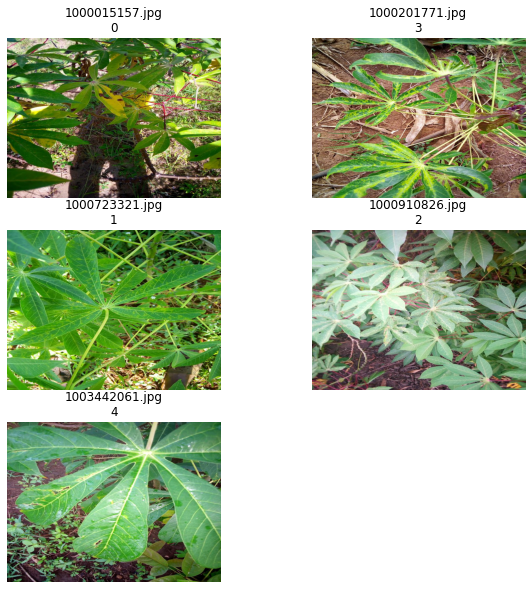

In [12]:
# Image sample from 5 different classes
sample_images = ['1000015157.jpg','1000723321.jpg','1000910826.jpg','1000201771.jpg','1003442061.jpg']
sample_images_df = train_labels[train_labels.image_id.isin(sample_images)]
plt.figure(figsize=(10,10))
for ind, (image_id, label) in enumerate(zip(sample_images_df.image_id, sample_images_df.label)):
    plt.subplot(3, 2, ind + 1)
    image = cv2.imread(os.path.join(WORK_DIR, "train_images", image_id))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.title('{}\n{}'.format(image_id,label))
    plt.imshow(image)
    plt.axis("off")
    
plt.show()

#### <b>Data Discovery & Imbalance</b>

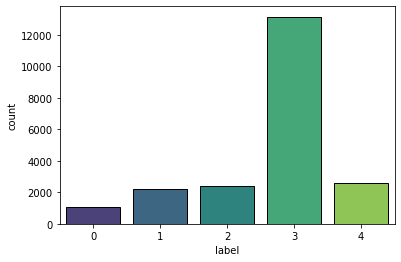

In [13]:
sns.countplot(train_labels.label, edgecolor = 'black',
              palette = sns.color_palette("viridis", 5))
plt.show()

There is imbalanced data with most images tied to the third class: "Cassava Mosaic Disease (CMD)". Let's see how the model performs with this imbalanced dataset. For future project iterations, I might consider upsampling the other classes to enhance the model.

<b>Why Not Adjust Imbalanced Data?</b> Literature suggests that by applying weights inside the CNN, this proves to mitigate any data imabalance issues.

As studied in Songqing Yue when approaching a malware image classification problem, the performance of the model was degraded due to the "imbalance of malware families (classess)". To help reduce the issues that arise from imbalanced data, they proposed a simple solution by applying softmax weights in a final layer of their CNNs. As such, I have applied a softmax weight in our final layer of the CNN which I describe in a later section.[4]

#### <b>Cassava Disease Classification Examples</b>

Below section provides samples of 6 images from the 5 classes in the dataset. Note that in the healthy plan population, one can sometimes see brown or broken leaves. This is perfectly normal.

##### Sample Photos of Dominant Class, Cassava Mosaic Disease (CMD)

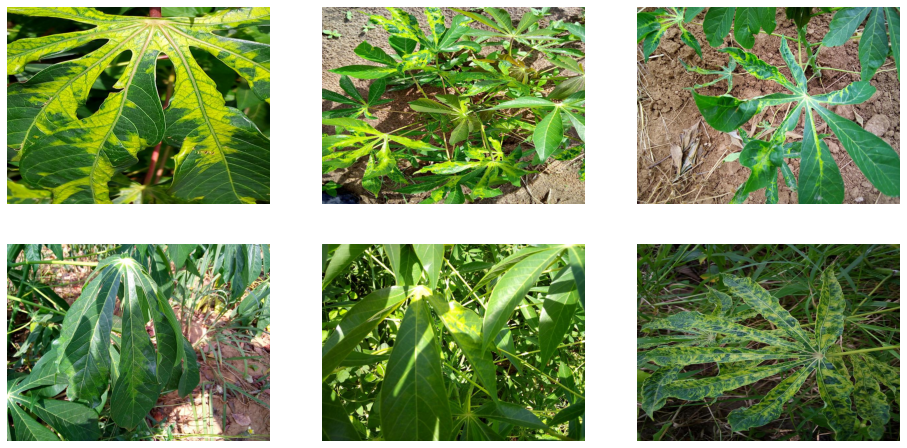

In [14]:
sample = train_labels[train_labels.label == 3].sample(6)
plt.figure(figsize=(16, 8))
for ind, (image_id, label) in enumerate(zip(sample.image_id, sample.label)):
    plt.subplot(2, 3, ind + 1)
    image = cv2.imread(os.path.join(WORK_DIR, "train_images", image_id))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.axis("off")
    
plt.show()

##### Sample Photos of Cassava Bacterial Blight (CBB)

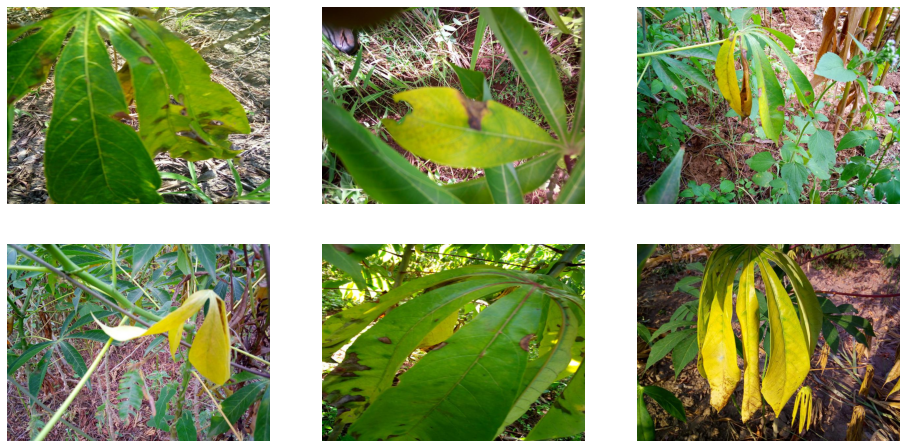

In [15]:
sample = train_labels[train_labels.label == 0].sample(6)
plt.figure(figsize=(16, 8))
for ind, (image_id, label) in enumerate(zip(sample.image_id, sample.label)):
    plt.subplot(2, 3, ind + 1)
    image = cv2.imread(os.path.join(WORK_DIR, "train_images", image_id))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.axis("off")
    
plt.show()

##### Sample Photos of Cassava Brown Streak Disease (CBSD)

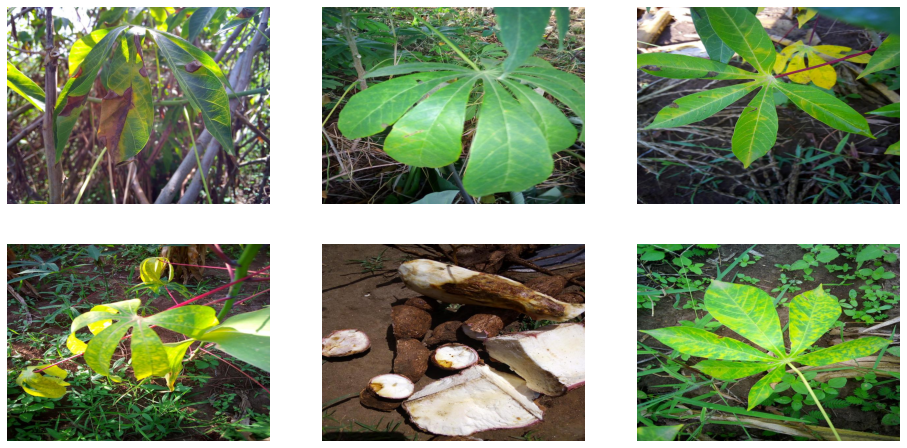

In [16]:
sample = train_labels[train_labels.label == 1].sample(6)
plt.figure(figsize=(16, 8))
for ind, (image_id, label) in enumerate(zip(sample.image_id, sample.label)):
    plt.subplot(2, 3, ind + 1)
    image = cv2.imread(os.path.join(WORK_DIR, "train_images", image_id))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.axis("off")
    
plt.show()

##### Sample Photos of Cassava Green Mottle (CGM)

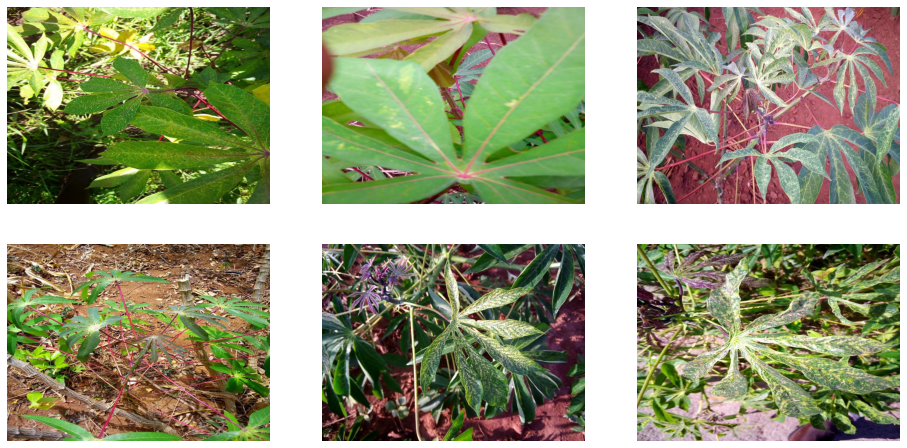

In [17]:
sample = train_labels[train_labels.label == 2].sample(6)
plt.figure(figsize=(16, 8))
for ind, (image_id, label) in enumerate(zip(sample.image_id, sample.label)):
    plt.subplot(2, 3, ind + 1)
    image = cv2.imread(os.path.join(WORK_DIR, "train_images", image_id))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.axis("off")
    
plt.show()

##### Sample Photos of healthy plants

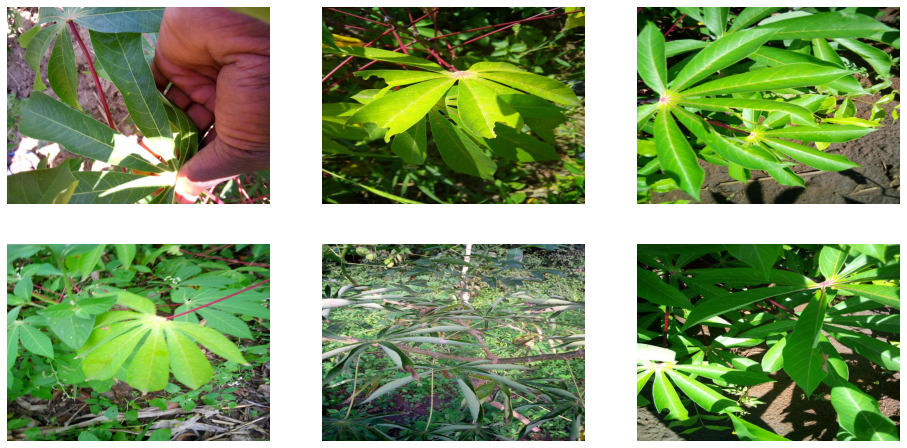

In [18]:
sample = train_labels[train_labels.label == 4].sample(6)
plt.figure(figsize=(16, 8))
for ind, (image_id, label) in enumerate(zip(sample.image_id, sample.label)):
    plt.subplot(2, 3, ind + 1)
    image = cv2.imread(os.path.join(WORK_DIR, "train_images", image_id))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.imshow(image)
    plt.axis("off")
    
plt.show()

#### <b>The baseline level of accuracy</b>

In [19]:
y_pred = [3] * len(train_labels.label)
print('The baseline accuracy: %.3f' 
      %accuracy_score(y_pred, train_labels.label))

The baseline accuracy: 0.615


Our future model must have validation accuracy better than 61.5% to conclude that our model performs better than the baseline level of accuracy.

## <b>Data Preprocessing</b>

An important step of any CNN is to preprocess our images: This ensures that the CNN has plenty of image variability and will help mitigate overfitting. Additionally, I can use pre-built keras functions to split image data into training & testing datsets.

In this project, I applied ImageDataGenerator as a test time augmentation technique to split the sample data into 20% validation images; 80% training images. I also performed some data augementation to flip, rotation, zoom, and shear the intensity of the image. 

Note also for ease of use, I create variables to store batch size, steps per epoch, validation steps, # of epochs in the CNN, and the target size of the image (I can assume all images are colored so TARGET_SIZE is used to adjust the image pixels to an appropriate size that the CNN can easily interpet).

<b>Why Image Rotation Augmentation?</b> In a study conducted by Li, Rui, et al in 2019, they were able to improve image detection of pests found on crops by using both multi-scale and rotation augmentation, rotating the images 3 consecutive times.[5] In this project, I use a rotation range of 5.

In [20]:
BATCH_SIZE = 16
STEPS_PER_EPOCH = len(train_labels)*0.8 / BATCH_SIZE
VALIDATION_STEPS = len(train_labels)*0.2 / BATCH_SIZE
EPOCHS = 10
TARGET_SIZE = 299

<b>Why Batch Size of 16?</b> I chose smaller batch sizes so that the model would have a wider epochs. Note this when I fit the model to the dataset.

In [21]:
train_labels.label = train_labels.label.astype('str')
#validation_split parameter allows for us to split 20% of the data into the validation set automatically without train test split
#Then you can allow .flow_from_dataframe to breakout the train versus validation in the data
train_generator = ImageDataGenerator(validation_split = 0.2,
                                     preprocessing_function = None,
                                     zoom_range = 0.2,
                                     cval = 0.2,
                                     horizontal_flip = True,
                                     vertical_flip = True,
                                     rotation_range = 5,
                                     fill_mode = 'constant',
                                     shear_range = 0.2,
                                     height_shift_range = 0.2,
                                     width_shift_range = 0.2) \
    .flow_from_dataframe(train_labels,
                         directory = os.path.join(WORK_DIR, "train_images"),
                         subset = "training",
                         x_col = "image_id",
                         y_col = "label",
                         target_size = (TARGET_SIZE, TARGET_SIZE),
                         batch_size = BATCH_SIZE,
                         class_mode = "sparse")

validation_generator = ImageDataGenerator(validation_split = 0.2) \
    .flow_from_dataframe(train_labels,
                         directory = os.path.join(WORK_DIR, "train_images"),
                         subset = "validation",
                         x_col = "image_id",
                         y_col = "label",
                         target_size = (TARGET_SIZE, TARGET_SIZE),
                         batch_size = BATCH_SIZE,
                         class_mode = "sparse")

Found 17118 validated image filenames belonging to 5 classes.
Found 4279 validated image filenames belonging to 5 classes.


#### <b>Sample Output of Training Image Augmentation</b>

Below is an example of how we augmented our training images before putting into the CNN. I may want to try other image augmentation techniques in the future, but for the purposes of this exercise, I wanted to recreate how a farmer might take pictures of the plants so I've rotated and cropped the images accordingly.

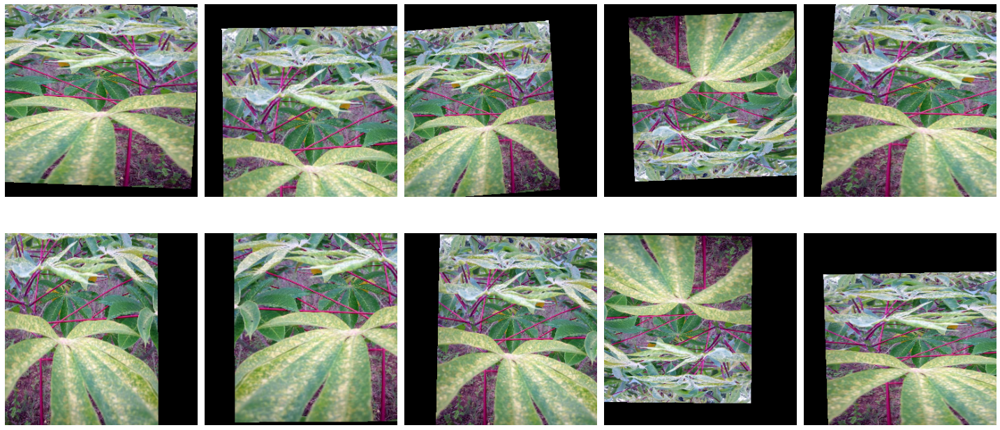

In [22]:
aug_trainimages = [train_generator[0][0][0]/255 for i in range(10)]
fig, axes = plt.subplots(2, 5, figsize = (20, 10))
axes = axes.flatten()
for img, ax in zip(aug_trainimages, axes):
    ax.imshow(img)
    ax.axis('off')
plt.tight_layout()
plt.show()

## <b>Modeling & Results</b>

EfficientNet architecture in CNNs have proven viable as transfer learning architecture. In an ongoing study first conducted in May 2019, Tan, Mingxing, and Quoc V. Le. explored the use of EfficientNet models, especially when applied in a resource constrained environment. In their study, they were able to determine that EfficientNet's can outperform older architectures like MobileNets and ResNets when providing the right balance of network depth, width, and resolution.[6]

I will apply transfer learning by leveraging EfficientNetB4 in the initial layers of my model; I will then apply 2 additional layers, GlobalAveragePooling2D and a 5-unit dense layer with a 'Softmax' activation, to distill the output of the model into the 5 distinct classifications and to adjust for the imbalanced data. Note also that EfficientNetB4 will be my baseline CNN for all future improvements made to the model. Given the resource limitations in this setting, EfficientNet4b was able to run under 1 hour and produced favorable results.

Another important element to a resource efficient CNN is the application of callbacks. In this exercise, I use a model checkpoint callback to save the model anytime validation loss improved, early stopping to stop the CNN from running once the validation loss stop improving after 5 epochs, reducing the learning rate when a metric has stopped improving, and lastly the tensorboard callback to provide more enhanced visualizations.

### <b> Modeling </b>

In [23]:
def create_model():
    model = models.Sequential()

    model.add(EfficientNetB4(include_top = False, weights = 'imagenet',
                             input_shape = (TARGET_SIZE, TARGET_SIZE, 3)))
    
    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(5, activation = "softmax"))

    model.compile(optimizer = Adam(lr = 0.001),
                  loss = "sparse_categorical_crossentropy",
                  metrics = ["acc"])
    return model

In [24]:
model = create_model()


71688192/71686520 [==============================] - 2s 0us/step


In [25]:
model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
efficientnetb4 (Functional)  (None, 10, 10, 1792)      17673823  
_________________________________________________________________
global_average_pooling2d (Gl (None, 1792)              0         
_________________________________________________________________
dense (Dense)                (None, 5)                 8965      
Total params: 17,682,788
Trainable params: 17,557,581
Non-trainable params: 125,207
_________________________________________________________________


In [26]:
log_dir = "logs/fit/" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S")

tensorboard_callback = tf.keras.callbacks.TensorBoard(log_dir=log_dir, histogram_freq=1)
model_save = ModelCheckpoint('./best_baseline_model.h5', 
                             save_best_only = True, 
                             save_weights_only = True,
                             monitor = 'val_loss', 
                             mode = 'min', verbose = 1)
early_stop = EarlyStopping(monitor = 'val_loss', min_delta = 0.001, 
                           patience = 5, mode = 'min', verbose = 1,
                           restore_best_weights = True)
reduce_lr = ReduceLROnPlateau(monitor = 'val_loss', factor = 0.3, 
                              patience = 2, min_delta = 0.001, 
                              mode = 'min', verbose = 1)

In [27]:
history = model.fit(
    train_generator,
    steps_per_epoch = STEPS_PER_EPOCH,
    epochs = EPOCHS,
    validation_data = validation_generator,
    validation_steps = VALIDATION_STEPS,
    callbacks = [tensorboard_callback,model_save, early_stop, reduce_lr]
    )

Epoch 1/10
   1/1069 [..............................] - ETA: 0s - loss: 1.5754 - acc: 0.2500WARNING:tensorflow:From /usr/local/lib/python3.6/dist-packages/tensorflow/python/ops/summary_ops_v2.py:1277: stop (from tensorflow.python.eager.profiler) is deprecated and will be removed after 2020-07-01.
Instructions for updating:
use `tf.profiler.experimental.stop` instead.
1070/1069 [==============================] - ETA: 0s - loss: 0.6533 - acc: 0.7735
Epoch 00001: val_loss improved from inf to 0.60247, saving model to ./best_baseline_model.h5
1070/1069 [==============================] - 578s 540ms/step - loss: 0.6533 - acc: 0.7735 - val_loss: 0.6025 - val_acc: 0.8196
Epoch 2/10
1070/1069 [==============================] - ETA: 0s - loss: 0.5086 - acc: 0.8249
Epoch 00002: val_loss improved from 0.60247 to 0.46338, saving model to ./best_baseline_model.h5
1070/1069 [==============================] - 574s 536ms/step - loss: 0.5086 - acc: 0.8249 - val_loss: 0.4634 - val_acc: 0.8373
Epoch 3/10


After 10 epochs, validation loss ended at 38%; validation accuracy ended at 87%.  That's an awesome baseline for a CNN!

### <b>Results</b>

When we review the average validation accuracy & loss from the 10 epochs, we see on average 85% accuracy & 44% loss. You can see that the validation loss plateaus around the 6th epoch and no longer improves; validation accuracy also plateaus around the 6th epoch with little improvement.

In [28]:
avg_acc = sum(history.history['acc'])/len(history.history['acc'])
avg_val_acc = sum(history.history['val_acc'])/len(history.history['val_acc'])
avg_loss = sum(history.history['loss'])/len(history.history['loss'])
avg_val_loss = sum(history.history['val_loss'])/len(history.history['val_loss'])

print('Training produced an average accuracy of %.3f and average loss of %.3f' % (avg_acc,avg_loss))
print('Validation produced an average accuracy of %.3f and average loss of %.3f' % (avg_val_acc,avg_val_loss))

Training produced an average accuracy of 0.845 and average loss of 0.453
Validation produced an average accuracy of 0.849 and average loss of 0.462


<b>Note:</b> If you would like a more interactive representation of the results of the CNN, please download & open this notebook using Google Collab.  For the interest of showing how our model ran in Github, I provided simple plots using Matplotlib.

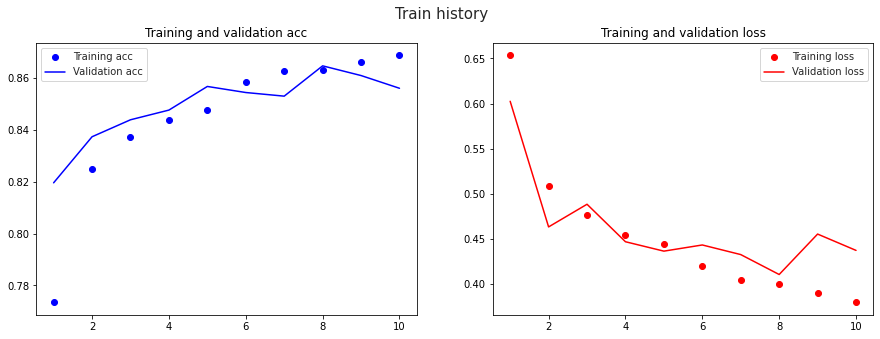

In [29]:
acc = history.history['acc']
val_acc = history.history['val_acc']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
sns.set_style("white")
plt.suptitle('Train history', size = 15)

ax1.plot(epochs, acc, "bo", label = "Training acc")
ax1.plot(epochs, val_acc, "b", label = "Validation acc")
ax1.set_title("Training and validation acc")
ax1.legend()

ax2.plot(epochs, loss, "bo", label = "Training loss", color = 'red')
ax2.plot(epochs, val_loss, "b", label = "Validation loss", color = 'red')
ax2.set_title("Training and validation loss")
ax2.legend()

plt.show()

In [30]:
model.save('./baseline_model.h5')

#### Prediction Accuracy against sample_submission.csv

Since the competition is still active as of December 2020, Kaggle has provided us with only 1 record to test out the label prediction of our model. Importing the sample_submission.csv containing the true label assigned to the image, we can confirm that our model accurately predicts the same label (yay!)

Once the competition ends in February 2021, I will perform a more comprehensive comparison of the model's ability to accurately predict labels assigned to images.

In [31]:
ss = pd.read_csv(os.path.join(WORK_DIR, "sample_submission.csv"))
ss

,image_id,label
0,2216849948.jpg,4


In [32]:
preds = []

for image_id in ss.image_id:
    image = Image.open(os.path.join(WORK_DIR,  "test_images", image_id))
    image = image.resize((TARGET_SIZE, TARGET_SIZE))
    image = np.expand_dims(image, axis = 0)
    preds.append(np.argmax(model.predict(image)))

ss['label'] = preds
ss

,image_id,label
0,2216849948.jpg,4


#### Tensorboard visualization

I used Tensorboard to provide a visual representation on the accuracy and loss per each epoch (you will need to open the notebook in Google Collab to view the Tensorboard as it does not render in GitHub). 

In [33]:
%tensorboard --logdir logs/fit

Output hidden; open in https://colab.research.google.com to view.

## Discussion, Conclusion, and Summary

The results of this analysis show that image recognition with transfer learning from a convolutional neural network, like EfficientNetB4, is a powerful tool for high accuracy and low loss in detecting cassava disease classes. This methodology helps mitigate the complex and labor-intensive process to extract features from images in order to train models, and can be deployed easily on a mobile device on phones with low resolution like those possibly carried by Subsaharan African farmers. Transfer learning is also capable of applying common machine learning methods by retraining the vectors produced by the trained model on new class data.

So what's next? I'd like to explore the following during a future iteration of this project:

1. <b>Additional Test Time Augmentation (TTA):</b> Shanmugam, Divya, et al. published a paper in 2020 that highlighted how TTA - the aggregation of predictions across transformed versions of CNN input - can be applied to increase scores of a baseline model.[7] We did apply some test time augmentation technique using Keras prebuilt image augmentation, I would like to try other techniques to shift the images to fine tune the model.
1. <b>Image Scale Variation:</b> If/When I am not faced with resource constraints, I would like to try scaling images larger than 299 x 299 x 3. I'd like to first start with 448 x 448 x 3 to see if a larger image improves the CNNs ability to predict image classes.
1. <b>Transfer Learning Variations:</b> In future iterations and if/when I do not face further resource contraints, I'd like to compare transfer learning from other architectures like Xception to see if they produce higher validations scores.
1. <b>Oversampling to reduce imbalanced data:</b> Suprisingly, our model still performed very well even with the imbalanced dataset. For future project interations, I would like to try oversampling other classification groups to rectify any loss or accuracy deprivation as a result of imbalanced data tied to CMD class.

## References & Contributions
[1] Bart RS, Taylor NJ (2017) New opportunities and challenges to engineer disease resistance in cassava, a staple food of African small-holder farmers. PLoS Pathog 13(5):e1006287. https://doi.org/10.1371/journal. ppat.1006287

[2] Ramcharan A, Baranowski K, McCloskey P, Ahmed B, Legg J and Hughes DP (2017) Deep Learning for Image-Based Cassava Disease Detection. Front. Plant Sci. 8:1852. doi: 10.3389/fpls.2017.01852

[3] Mcrops, creating diagnostic tools for diagnosing viral crop diseases in cassava crops. http://air.ug/mcrops/

[4] Hensman, Paulina, and David Masko. "The impact of imbalanced training data for convolutional neural networks." Degree Project in Computer Science, KTH Royal Institute of Technology (2015).

[5] Li, Rui, et al. "An effective data augmentation strategy for CNN-based pest localization and recognition in the field." IEEE Access 7 (2019): 160274-160283.

[6] Tan, Mingxing, and Quoc V. Le. "Efficientnet: Rethinking model scaling for convolutional neural networks." arXiv preprint arXiv:1905.11946 (2019).

[7] Shanmugam, Divya, et al. "When and Why Test-Time Augmentation Works." arXiv preprint arXiv:2011.11156 (2020).

## File clean up & saving models locally

In [34]:
ss.to_csv('submission.csv', index = False)

In [35]:

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [36]:
os.chdir(os.getcwd()+'/drive/MyDrive/Cassava-Leaf-Disease-Classification')
print('The Current Working Directory is: ',os.getcwd())

The Current Working Directory is:  /content/drive/.shortcut-targets-by-id/1MGR9cqxVie9uSdExzuOivIS31FTUEeRE/Cassava-Leaf-Disease-Classification
